In [1]:
from astropy.io import fits
import glob
import numpy as np
import matplotlib.pyplot as plt

In [2]:
bias_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\BiasImages\*.fit"))
star1_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Star1\*.fit"))
star2_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Star2\*.fit"))
star3_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Star3\*.fit"))
twilight_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\TwilightFlats\*.fit"))
dark1_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Darks\15s\*.fit"))
dark2_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Darks\45s\*.fit"))
dark3_list = sorted(glob.glob(r"D:\Desktop\Autumn 26\Observational Astronomy\Lab1\Darks\30s\*.fit"))

biasImages = np.zeros((20, 3522, 4656), np.int16)
star1 = np.zeros((10, 3522, 4656), np.int16)
star2 = np.zeros((10, 3522, 4656), np.int16)
star3 = np.zeros((10, 3522, 4656), np.int16)
twilightFlats = np.zeros((100, 3522, 4656), np.int16)
dark1 = np.zeros((10, 3522, 4656), np.int16)
dark2 = np.zeros((10, 3522, 4656), np.int16)
dark3 = np.zeros((10, 3522, 4656), np.int16)

In [3]:
def real_counts(m):
    return (m/16) + 1

In [4]:
for i in range(10):
    for j in range(10):
        f = fits.open(twilight_list[10*i + j])
        twilightFlats[10*i + j] = real_counts(f[0].data)
    for j in range(2):
        f = fits.open(bias_list[10*j + i])
        biasImages[10*j + i] = real_counts(f[0].data)
    s1 = fits.open(star1_list[i])
    star1[i] = real_counts(s1[0].data)
    s2 = fits.open(star2_list[i])
    star2[i] = real_counts(s2[0].data)
    s3 = fits.open(star3_list[i])
    star3[i] = real_counts(s3[0].data)
    d1 = fits.open(dark1_list[i])
    dark1[i] = real_counts(d1[0].data)
    d2 = fits.open(dark2_list[i])
    dark2[i] = real_counts(d2[0].data)
    d3 = fits.open(dark3_list[i])
    dark3[i] = real_counts(d3[0].data)
    

In [5]:
#plt.imshow(star1[0], vmin = 0, vmax = 2500)
#plt.colorbar(label="counts")

In [6]:
#plt.imshow(biasImages[9], vmin = 0, vmax = 300)
#plt.colorbar(label="counts")

153.7


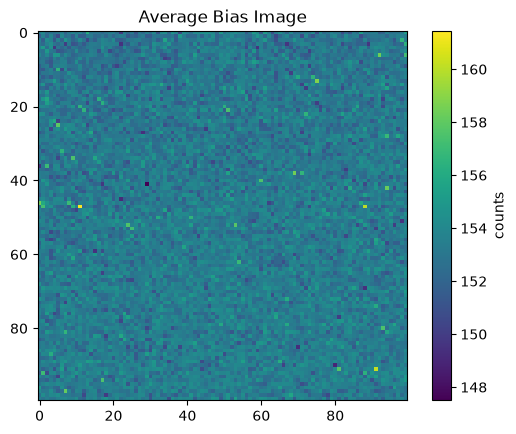

In [7]:
meanBI = np.mean(biasImages, axis=0)
medianBI = np.median(meanBI)
print(medianBI)
plt.imshow(meanBI[0:100,0:100])
plt.title("Average Bias Image")
plt.colorbar(label="counts")
plt.savefig("fig_meanBI.jpg")

In [8]:
#rand = np.random.choice(100, 10, replace=False)
#print(rand)

#samp = np.array([5, 15, 25, 35, 45, 55, 65, 75, 85, 95])
a = np.zeros((100))
for i in range(100):
    a[i] = i
samp = a[::4]

In [9]:
medianTF = np.median(twilightFlats, axis=0)

In [10]:
normTF = np.zeros((samp.size, 3522, 4656))

In [11]:
z_iMed = np.zeros((samp.size))
for i in range(samp.size):
    z_iMed[i] = np.median(twilightFlats[int(samp[i])] - meanBI)

In [12]:
for h in range (samp.size):
    normTF[h] = (twilightFlats[int(samp[h])] - meanBI) / z_iMed[h]
    print(h)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24


In [13]:
medNormTF = np.median(normTF, axis=0)

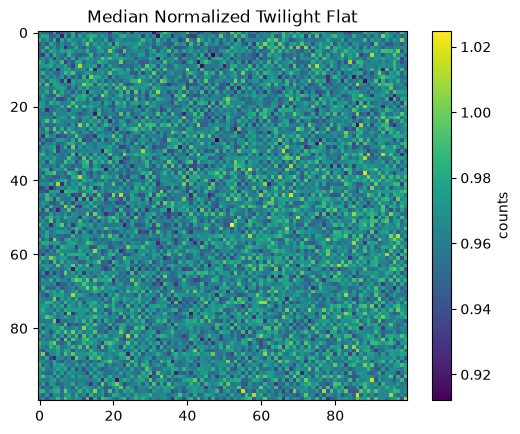

In [14]:
plt.imshow(medNormTF[0:100,0:100])
plt.colorbar(label="counts")
plt.title("Median Normalized Twilight Flat")
plt.savefig("MedNormTF.jpg")

In [15]:
diffBI = biasImages[0] - biasImages[1]
print(np.mean(diffBI))

0.03076452675475314


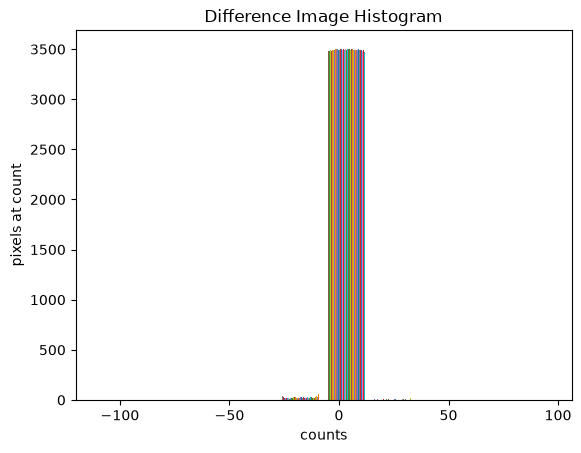

In [30]:
plt.hist(diffBI)
plt.title("Difference Image Histogram")
plt.xlabel("counts")
plt.ylabel("pixels at count")
plt.savefig("figDiffBI.jpg")

In [17]:
readNoise = np.std(diffBI)/(2**0.5)

In [26]:
print(readNoise)

2.1272123498286604


In [18]:
meanDark1 = np.mean(dark1)
meanDark2 = np.mean(dark2)
meanDark3 = np.mean(dark3)

In [19]:
#a = sci image, b = mean dark value
def corrSciImg(s, d):
    return (s - d - meanBI) / medNormTF

In [20]:
img1_Alioth = corrSciImg(star1[0], meanDark1)
img2_Grumium = corrSciImg(star2[5], meanDark2)
img3_Sadalsuud = corrSciImg(star3[0], meanDark3)

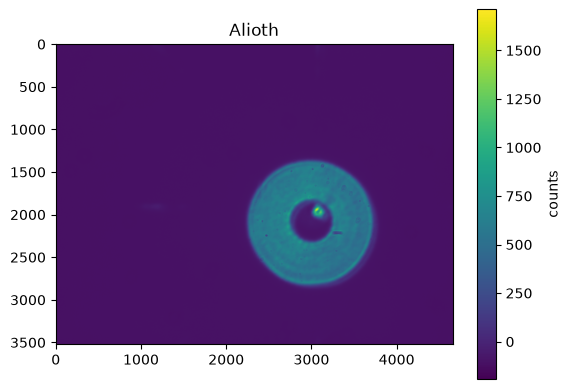

In [31]:
plt.imshow(img1_Alioth)
plt.colorbar(label="counts")
plt.title("Alioth")
plt.savefig("Alioth.jpg")

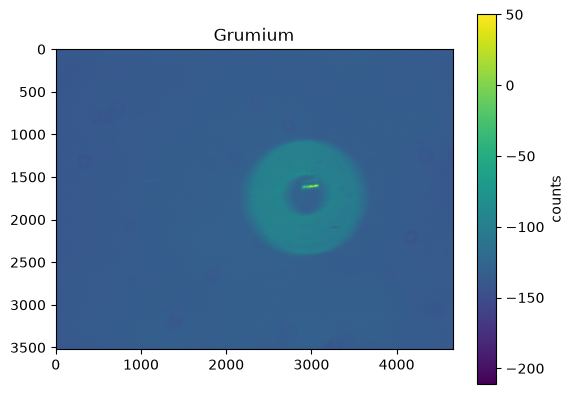

In [32]:
plt.imshow(img2_Grumium, vmax=50)
plt.colorbar(label="counts")
plt.title("Grumium")
plt.savefig("Grumium.jpg")

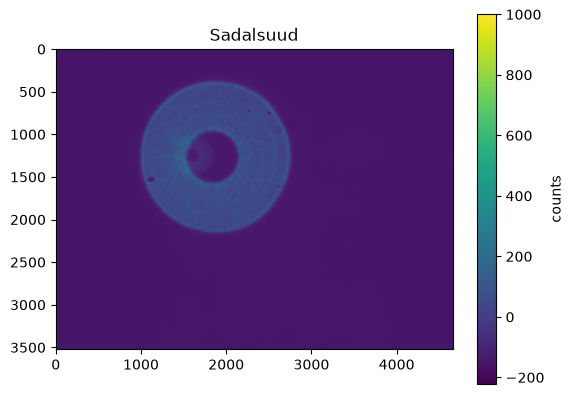

In [33]:
plt.imshow(img3_Sadalsuud, vmax=1000)
plt.colorbar(label="counts")
plt.title("Sadalsuud")
plt.savefig("Sadalsuud.jpg")